In [25]:
# pip install langchain_openai

In [26]:
# pip install langchain_gemini

In [27]:
from langgraph.graph import StateGraph, START, END
from  langchain_core.messages import HumanMessage, SystemMessage
from pydantic import BaseModel, Field
from langchain_openai import ChatOpenAI
from dotenv import load_dotenv
load_dotenv()
# eg
# from langchain_gemini import ChatGemini


True

In [28]:
llm = ChatOpenAI(model="gpt-4o-mini")
# llm_gemini = ChatGemini(model="gemini-1.5-turbo")
# llm_gemini.invoke(hi)

In [29]:
# state definations
from typing import TypedDict, Literal

class SentimentState(TypedDict):
    original_tweet: str
    sentiment: str
    confidence: float
    response_tweet: str


In [30]:
class SentimentAnalysis(BaseModel):
    sentiment: Literal["positive", "negative"] = Field(description="The sentiment classification either positive or negative")
    confidence: float = Field(ge=0, le=1.0, description="Confidence score from 0.0 to 1.0")
    reason: str = Field(description="Brief explanation")

In [31]:
# node 1 

def analyze_sentiment(state: SentimentState):
    tweet = state["original_tweet"]
    messages = [
        SystemMessage("Analyze sentiment and provide the structured output. Use 0 to 1.0 scale for confidence. lower is negative and higher is positive"),
        HumanMessage(tweet)
    ]
    structured_llm = llm.with_structured_output(SentimentAnalysis)

    analysis = structured_llm.invoke(messages)
    return {'sentiment': analysis.sentiment,
            'confidence': analysis.confidence}




In [32]:
def generate_postive_response(state: SentimentState):
    
    print(f"current state in positive respone node: {state}")

    messages = [
        SystemMessage(f"""Generate a warm response to this positive tweet under 280 chars.
                      Confidence: {state['confidence']}. High confidence means be enthusiastic otherwise be friendly."""),
        HumanMessage(state['original_tweet'])
    ]

    response = llm.invoke(messages)

    return {'response_tweet': response.content.strip()}

def generate_negative_response(state: SentimentState):
    print(f"current state in negative respone node: {state}")

    messages = [
        SystemMessage(f"""Generate and empathetic response to this negative tweet under 280 chars.
                      If Confidence {state['confidence']} is very low then be empathetic otherwise 
                      be understanding."""),
        HumanMessage(state['original_tweet'])
    ]

    response = llm.invoke(messages)

    return {'response_tweet': response.content.strip()}


In [33]:
def route_by_sentiment(state: SentimentState):
    if state['sentiment'] == 'positive':
        return "positive_response"
    
    else:
        return "negative_response"

In [34]:
def test(state: SentimentState):
    print(f"current state in test node: {state}")
    return state

In [35]:
builder = StateGraph(SentimentState)
builder.add_node("decider", analyze_sentiment)
builder.add_node("positive_response", generate_postive_response)
builder.add_node("negative_response", generate_negative_response)
builder.add_node("route_by_sentiment", route_by_sentiment)


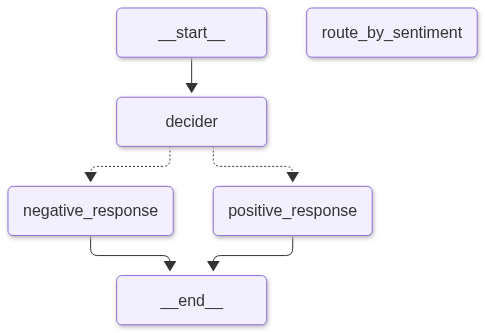

In [36]:
builder.add_edge(START, "decider")
builder.add_conditional_edges("decider",route_by_sentiment,["positive_response", "negative_response"])
builder.add_edge("positive_response", END)
builder.add_edge("negative_response", END)
graph = builder.compile()
graph

In [37]:
tweet = "what was previous questuions"

result = graph.invoke({'original_tweet': tweet})

current state in negative respone node: {'original_tweet': 'what was previous questuions', 'sentiment': 'negative', 'confidence': 0.85}


In [38]:
result

{'original_tweet': 'what was previous questuions',
 'sentiment': 'negative',
 'confidence': 0.85,
 'response_tweet': "I understand that you're feeling frustrated or confused about the previous questions. It's tough when things don't make sense, and I’m here to help clarify or support you! Please let me know what you need, and I'll do my best to assist you."}

In [39]:
tweet = 'very good but bot happy'
messages = [
    SystemMessage("Analyze sentiment and provide the structured output. Use 0 to 1.0 scale for confidence. lower is negative and higher is positive"),
    HumanMessage(tweet)
]

llm.invoke(messages).content

'{\n  "sentiment": "mixed",\n  "confidence": 0.6,\n  "details": {\n    "positive": "very good",\n    "negative": "not happy"\n  }\n}'

In [40]:
structured_llm = llm.with_structured_output(SentimentAnalysis)
structured_llm.invoke(messages)

SentimentAnalysis(sentiment='negative', confidence=0.4, reason='The phrase suggests dissatisfaction or disappointment despite an initial positive remark.')